# EDA: `raw_airport_reviews`

One notebook per raw Skytrax table (index in `eda.ipynb`). 

**Role of this table:** Fact table of airport reviews, one row per review. Joins to `raw_airports` on `airport_id`.

**Read-only:** the CSV in `data/` is only read. Cleaning below happens on an in-memory copy (`df`); the real cleaning rules are written later in dbt staging.

## Table of Contents

- [0. Setup](#sec-0)
  - [0.1 Imports](#sec-0-1)
  - [0.2 Config](#sec-0-2)
  - [0.3 Plot style](#sec-0-3)
  - [0.4 Helpers](#sec-0-4)
- [1. Look at the Big Picture](#sec-1)
  - [1.1 Frame the Problem](#sec-1-1)
  - [1.2 Questions & Hypotheses](#sec-1-2)
  - [1.3 Performance Measure (for later modelling)](#sec-1-3)
  - [1.4 Check the Assumptions](#sec-1-4)
- [2. Get the Data](#sec-2)
  - [2.1 Data Dictionary](#sec-2-1)
- [3. Data Cleaning (General)](#sec-3)
  - [3.1 Format Column Names](#sec-3-1)
  - [3.2 Format Data Body](#sec-3-2)
  - [3.3 Format Datatypes](#sec-3-3)
  - [3.4 Duplicates](#sec-3-4)
  - [3.5 Domain Sanity Checks](#sec-3-5)
- [4. Data Quality](#sec-4)
  - [4.1 Missing Values](#sec-4-1)
  - [4.2 Outliers](#sec-4-2)
- [5. Attribute Combination](#sec-5)
- [6. EDA](#sec-6)
  - [6.0 Classify Attributes](#sec-6-0)
  - [6.1 Univariate](#sec-6-1)
  - [6.2 Bivariate](#sec-6-2)
  - [6.3 Multivariate](#sec-6-3)
- [7. Summary of Findings](#sec-7)
- [8. Hand-off to Modelling](#sec-8)

# 0. Setup<a id="sec-0"></a>

## 0.1 Imports<a id="sec-0-1"></a>

In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

## 0.2 Config<a id="sec-0-2"></a>

Everything dataset-specific lives here. Column names are the **snake_case** names produced in section 3.1.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()

TABLE = "airport_reviews"            # name of the file in data/
DATA_PATH = ROOT / "data" / f"{TABLE}.csv"
TARGET = "recommended"        # yes/no: the business question is what goes with a recommendation
PROBLEM_TYPE = "classification"   # nothing is predicted: this only switches on the target views of the template
ID_COLS = ['review_id']       # identifiers: excluded from analysis
CAT_COLS = ['airport_id']     # force these to categorical; None = auto-detect
CAT_MAX_UNIQUE = 15           # numeric columns with <= this many values are treated as discrete
HIGH_CORR = 0.8               # |r| above this is flagged as multicollinearity
TOP_N_CATEGORIES = 10         # categories shown per bar chart

SAVE_FIGS = False             # True writes every figure to FIG_DIR
FIG_DIR = ROOT / "reports" / "figures"
RANDOM_STATE = 42

## 0.3 Plot style<a id="sec-0-3"></a>

One consistent look: blue for single-series charts, a fixed categorical order for
hue splits (max 3 groups per chart), and a blue ↔ gray ↔ red diverging map for correlations.

In [3]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
MAIN = PALETTE[0]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#86b6ef", "#f0efec", "#f19a99", "#b52f2e"])

sns.set_theme(
    style="whitegrid",
    palette=PALETTE,
    rc={
        "axes.edgecolor": "#c3c2b7",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#52514e",
        "grid.color": "#ecebe7",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "lines.linewidth": 2,
        "figure.dpi": 100,
    },
)

## 0.4 Helpers<a id="sec-0-4"></a>

In [4]:
def to_snake_case(df):
    """CamelCase / spaces / dashes -> snake_case column names."""
    df = df.copy()
    df.columns = (
        df.columns.str.strip()
        .str.replace(r"(?<=[a-z0-9])(?=[A-Z])", "_", regex=True)
        .str.replace(r"[\s\-/]+", "_", regex=True)
        .str.lower()
    )
    return df


def save_fig(fig, name):
    if SAVE_FIGS and name:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=110, bbox_inches="tight")


def plot_grid(columns, plot_fn, ncols=4, height=3.0, title=None, name=None, shared_legend=False):
    """Draw plot_fn(col, ax) for every column in a grid of subplots.

    shared_legend=True replaces per-panel legends with one legend above the grid.
    """
    columns = list(columns)
    if not columns:
        print("Nothing to plot.")
        return
    nrows = math.ceil(len(columns) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, height * nrows), squeeze=False)
    axes = axes.ravel()
    for ax, col in zip(axes, columns):
        plot_fn(col, ax)
        ax.set_title(col)
    for ax in axes[len(columns):]:
        ax.axis("off")
    fig.tight_layout()
    legend = axes[0].get_legend()
    if shared_legend and legend:
        handles, labels = legend.legend_handles, [t.get_text() for t in legend.get_texts()]
        fig.legend(handles, labels, title=legend.get_title().get_text(), loc="lower center",
                   bbox_to_anchor=(0.5, 1.0), ncol=len(labels), frameon=False)
        for ax in axes:
            if ax.get_legend():
                ax.get_legend().remove()
    if title:
        fig.suptitle(title, fontsize=13, fontweight="bold", y=1.0 + (0.7 / fig.get_figheight() if shared_legend and legend else 0))
    save_fig(fig, name)
    plt.show()


def missing_report(df):
    """Count and % of nulls per column (only columns with nulls)."""
    report = pd.DataFrame({
        "n_missing": df.isna().sum(),
        "pct_missing": df.isna().mean() * 100,
        "dtype": df.dtypes.astype(str),
    })
    return report[report.n_missing > 0].sort_values("n_missing", ascending=False)


def outlier_report(df, columns, k=1.5):
    """IQR-based outlier counts. Detection only - nothing is removed."""
    rows = []
    for col in columns:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - k * iqr, q3 + k * iqr
        n_out = int(((s < lo) | (s > hi)).sum())
        rows.append({"column": col, "lower": lo, "upper": hi, "min": s.min(), "max": s.max(),
                     "n_outliers": n_out, "pct_outliers": 100 * n_out / len(s)})
    return pd.DataFrame(rows).set_index("column").sort_values("n_outliers", ascending=False)


def classify_columns(df, target=None, id_cols=(), cat_cols=None, cat_max_unique=15):
    """Split columns into constant / binary / categorical / discrete / continuous."""
    groups = {"constant": [], "binary": [], "categorical": [], "discrete": [], "continuous": []}
    forced_cat = set(cat_cols or [])
    for col in df.columns:
        if col in id_cols or col == target:
            continue
        n = df[col].nunique(dropna=True)
        if n <= 1:
            groups["constant"].append(col)
        elif n == 2:
            groups["binary"].append(col)
        elif col in forced_cat or not pd.api.types.is_numeric_dtype(df[col]):
            groups["categorical"].append(col)
        elif n <= cat_max_unique:
            groups["discrete"].append(col)
        else:
            groups["continuous"].append(col)
    return groups

# 1. Look at the Big Picture<a id="sec-1"></a>

## 1.1 Frame the Problem<a id="sec-1-1"></a>

Answered before touching the data. Business context: the stakeholder is the Head of Customer Experience of a mid-size full-service airline, who decides how to split the yearly budget for improving the customer experience.

* **What is the business objective?**
  Decide which airport aspects to raise with airports (queuing, cleanliness, seating, signs, food, shopping, staff, wifi). This is lower priority and built last.
* **How will the output be used?**
  The Head of Customer Experience uses it to prepare talks with big airports about the aspects that pull the experience down.
* **What does the target look like?** (regression / classification / none)
  `recommended` (yes/no), so a classification-style view. Nothing is predicted: we only look at which aspects go together with a customer recommending the airline.
* **What would a useful result be?**
  A ranked list of airport aspects by how strongly they go with `recommended`, and how departure, arrival and transit differ.

Main question (all review tables): *which service aspect goes together most with customers recommending the airline, and where is the airline weaker than its peers?*

## 1.2 Questions & Hypotheses<a id="sec-1-2"></a>

The questions this EDA must answer. Each one maps to a section below. Q-numbers follow the business question list; `D1` is the data-readiness check that comes first.

| # | Question | Answered in |
|---|---|---|
| D1 | Can we trust the data enough to answer (nationality text, duplicates, missing values)? | 3, 4 |
| Q1 | At big airports (at least 100 reviews), which aspect pulls the experience down? | 6.1, 6.3.1 |
| Q2 | Which airport aspect goes together most with `recommended`? | 6.2 |
| Q3 | How does the experience differ between departure, arrival and transit? | 6.3.1 |
| Q4 | Are some ratings redundant? | 6.3 |

## 1.3 Performance Measure (for later modelling)<a id="sec-1-3"></a>

Pick now so the EDA looks at the right things (e.g. skewed target → consider RMSLE / log target).

* **Regression:** RMSE, MAE, MAPE, RMSLE, adjusted R²
* **Classification:** ROC-AUC, PR-AUC, F1, precision/recall, confusion matrix (check class balance in 6.1)

*Here there is no model, so the "performance measure" is a business one: the recommend rate and the mean-score gap per aspect (built later in the marts).*

## 1.4 Check the Assumptions<a id="sec-1-4"></a>

To confirm with the data owner / stakeholder.

* `review_id` is the primary key; one row = one airport review.
* `date_visit` is the first day of the visit month, not the exact day.
* Airport reviews cannot be linked to an airline reliably, only to an airport.
* Airport reviews only have an airport, not an airline, so they cannot be tied to an airline reliably.
* Reviews are voluntary opinions posted on Skytrax, not a random survey: results describe people who write reviews.
* `recommended` measures how appealing an airline is, not whether the ticket was bought. We say "goes with", never "causes".
* Scores differ strongly by region and nationality, so only compare like with like (same cabin, same region).

# 2. Get the Data<a id="sec-2"></a>

In [5]:
raw = pd.read_csv(DATA_PATH)   # the CSV is only read, never changed
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

49,505 rows x 20 columns


In [6]:
# Take a look at the top 5 rows
raw.head()

,review_id,airport_id,verify,date_submitted,date_visit,customer_name,nationality,experience_at_airport,type_of_traveller,queuing_times,terminal_cleanliness,terminal_seating,terminal_signs,food_beverages,airport_shopping,airport_staff,wifi_connectivity,recommended,review,updated_at
0,1,9,False,2022-06-06,2022-03-01,Charles Smith 24,Netherlands,Arrival and Departure,Couple Leisure,5.00,5.00,5.00,5.00,5.00,5.00,5.00,NaN,True,"This 'newish' airport is compact, clean, spacious, bright and well designed....",2026-06-20 12:45:42
1,2,8,False,2017-03-05,2017-02-01,Wei Rivera 19,United Kingdom,Arrival and Departure,Business,2.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,True,Abuja airport is closing on 7 March for 6 weeks until 18 April for reconstru...,2026-06-20 12:45:42
2,3,8,False,2016-04-25,2016-04-01,George Rossi 28,Nigeria,Arrival Only,Solo Leisure,1.00,2.00,1.00,5.00,NaN,NaN,1.00,NaN,False,"For starters Abuja airport was super hot, no air conditioning or at least fa...",2026-06-20 12:45:42
3,4,8,False,2012-02-28,NaN,Emily Scott 2,United Kingdom,NaN,NaN,2.00,3.00,NaN,NaN,NaN,1.00,NaN,NaN,False,On arrival as we flew Business Class we were near the front of the line for ...,2026-06-20 12:45:42
4,5,8,False,2011-08-08,NaN,Aisha Brown,United States,NaN,NaN,1.00,3.00,NaN,NaN,NaN,1.00,NaN,NaN,False,Abuja international arrivals greets you with a long immigration line. Only o...,2026-06-20 12:45:42


In [7]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 49505 entries, 0 to 49504
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   review_id              49505 non-null  int64  
 1   airport_id             49505 non-null  int64  
 2   verify                 49505 non-null  bool   
 3   date_submitted         49505 non-null  str    
 4   date_visit             32183 non-null  str    
 5   customer_name          49505 non-null  str    
 6   nationality            46398 non-null  str    
 7   experience_at_airport  32256 non-null  str    
 8   type_of_traveller      32234 non-null  str    
 9   queuing_times          44287 non-null  float64
 10  terminal_cleanliness   44199 non-null  float64
 11  terminal_seating       28092 non-null  float64
 12  terminal_signs         31586 non-null  float64
 13  food_beverages         25303 non-null  float64
 14  airport_shopping       35139 non-null  float64
 15  airport_staff

In [8]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,"49,505.00",NaN,NaN,NaN,"24,753.00","14,291.01",1.00,"12,377.00","24,753.00","37,129.00","49,505.00"
airport_id,"49,505.00",NaN,NaN,NaN,470.86,265.96,1.00,255.00,521.00,661.00,"1,004.00"
verify,49505,2,False,38836,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_submitted,49505,6171,2014-09-01,68,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_visit,32183,144,2016-07-01,520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,49505,33296,Linda Roberts 16,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nationality,46398,1845,United Kingdom,15792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience_at_airport,32256,4,Departure Only,12337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type_of_traveller,32234,4,Couple Leisure,9637,NaN,NaN,NaN,NaN,NaN,NaN,NaN
queuing_times,"44,287.00",NaN,NaN,NaN,2.38,1.51,1.00,1.00,2.00,4.00,5.00


## 2.1 Data Dictionary<a id="sec-2-1"></a>

One row per column: what it means, its type, how many distinct values, and an example. The meanings are inferred from the column names and the data.

In [9]:
# Meaning of each column (from the column name and the data; correct them if you know better)
MEANINGS = {
    "review_id": "Review id (primary key)",
    "verify": "Verified review",
    "date_submitted": "Date the review was posted",
    "customer_name": "Reviewer name (ends with an anonymisation number)",
    "nationality": "Reviewer country",
    "recommended": "Reviewer recommends it",
    "review": "Free-text review",
    "updated_at": "Load time",
    "airport_id": "Airport reviewed, joins to `raw_airports`",
    "date_visit": "Month of the airport visit (first day of month)",
    "experience_at_airport": "Purpose of the airport visit (departure, arrival, transit, ...)",
    "type_of_traveller": "Trip type",
    "queuing_times": "Rating 1 to 5",
    "terminal_cleanliness": "Rating 1 to 5",
    "terminal_seating": "Rating 1 to 5",
    "terminal_signs": "Rating 1 to 5",
    "food_beverages": "Rating 1 to 5",
    "airport_shopping": "Rating 1 to 5",
    "airport_staff": "Rating 1 to 5",
    "wifi_connectivity": "Rating 1 to 5",
}

data_dictionary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "example": raw.iloc[0],
    "meaning": pd.Series(MEANINGS),
}).reindex(raw.columns)
data_dictionary

,dtype,n_unique,example,meaning
review_id,int64,49505,1,Review id (primary key)
airport_id,int64,1004,9,"Airport reviewed, joins to `raw_airports`"
verify,bool,2,False,Verified review
date_submitted,str,6171,2022-06-06,Date the review was posted
date_visit,str,144,2022-03-01,Month of the airport visit (first day of month)
customer_name,str,33296,Charles Smith 24,Reviewer name (ends with an anonymisation number)
nationality,str,1845,Netherlands,Reviewer country
experience_at_airport,str,4,Arrival and Departure,"Purpose of the airport visit (departure, arrival, transit, ...)"
type_of_traveller,str,4,Couple Leisure,Trip type
queuing_times,float64,5,5.00,Rating 1 to 5


# 3. Data Cleaning (General)<a id="sec-3"></a>

Cleaning that is safe to do on the **whole** dataset (no information from the target or test set is used).

## 3.1 Format Column Names<a id="sec-3-1"></a>

In [10]:
df = to_snake_case(raw)
df.columns.tolist()

['review_id',
 'airport_id',
 'verify',
 'date_submitted',
 'date_visit',
 'customer_name',
 'nationality',
 'experience_at_airport',
 'type_of_traveller',
 'queuing_times',
 'terminal_cleanliness',
 'terminal_seating',
 'terminal_signs',
 'food_beverages',
 'airport_shopping',
 'airport_staff',
 'wifi_connectivity',
 'recommended',
 'review',
 'updated_at']

In [11]:
# Manual renames, if any
# df = df.rename(columns={"unnamed:_0": "id"})

## 3.2 Format Data Body<a id="sec-3-2"></a>

Trim whitespace in text columns, then pull structured fields out of free-text columns.

In [12]:
text_cols = df.select_dtypes(include=["object", "string"]).columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
for col in text_cols:
    print(f"{col}: {df[col].nunique()} unique -> {[str(v)[:40] for v in df[col].unique()[:8]]}")

date_submitted: 6171 unique -> ['2022-06-06', '2017-03-05', '2016-04-25', '2012-02-28', '2011-08-08', '2011-04-14', '2010-01-31', '2009-05-24']
date_visit: 144 unique -> ['2022-03-01', '2017-02-01', '2016-04-01', 'nan', '2026-01-01', '2024-03-01', '2022-06-01', '2021-12-01']
customer_name: 33296 unique -> ['Charles Smith 24', 'Wei Rivera 19', 'George Rossi 28', 'Emily Scott 2', 'Aisha Brown', 'James Lewis 3', 'Raj Thompson 5', 'Susan Hall 20']
nationality: 1845 unique -> ['Netherlands', 'United Kingdom', 'Nigeria', 'United States', 'Brazil', 'India', 'Switzerland', 'Thailand']
experience_at_airport: 4 unique -> ['Arrival and Departure', 'Arrival Only', 'nan', 'Departure Only', 'Transit']
type_of_traveller: 4 unique -> ['Couple Leisure', 'Business', 'Solo Leisure', 'nan', 'Family Leisure']
review: 48818 unique -> ["This 'newish' airport is compact, clean,", 'Abuja airport is closing on 7 March for ', 'For starters Abuja airport was super hot', 'On arrival as we flew Business Class we ',

`customer_name` ends with an anonymisation number (e.g. `Joshua Torres 6`), which is not part of a real name. Strip it so the same person is written the same way.

In [13]:
has_suffix = df["customer_name"].str.contains(r"\s\d+$", na=False)
print(f"{has_suffix.sum():,} of {len(df):,} names end with a number")
df["customer_name"] = df["customer_name"].str.replace(r"\s+\d+$", "", regex=True)
pd.DataFrame({"before": raw["customer_name"], "after": df["customer_name"]}).loc[has_suffix].head(5)

47,722 of 49,505 names end with a number


,before,after
0,Charles Smith 24,Charles Smith
1,Wei Rivera 19,Wei Rivera
2,George Rossi 28,George Rossi
3,Emily Scott 2,Emily Scott
5,James Lewis 3,James Lewis


## 3.3 Format Datatypes<a id="sec-3-3"></a>

Check every column has the right type: dates → `datetime64`, flags → `int`/`bool`, labels → `category`.

In [14]:
df.dtypes.value_counts()

str        8
float64    8
int64      2
bool       2
Name: count, dtype: int64

In [15]:
# Dates must be datetime, flags must be nullable booleans (True / False / missing)
for col in [c for c in df.columns if c.startswith("date_") or c == "updated_at"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")
for col in [c for c in ["verify", "recommended"] if c in df.columns]:
    df[col] = df[col].astype("boolean")
df.dtypes.value_counts()

float64           8
str               5
datetime64[us]    3
int64             2
boolean           2
Name: count, dtype: int64

## 3.4 Duplicates<a id="sec-3-4"></a>

In [16]:
analysis_cols = [c for c in df.columns if c not in ID_COLS]
n_exact = df.duplicated().sum()
n_ignoring_id = df.duplicated(subset=analysis_cols).sum()
print(f"Exact duplicate rows:            {n_exact}")
print(f"Duplicates ignoring ID columns:  {n_ignoring_id}")
df[df.duplicated(subset=analysis_cols, keep=False)]

Exact duplicate rows:            0
Duplicates ignoring ID columns:  93


,review_id,airport_id,verify,date_submitted,date_visit,customer_name,nationality,experience_at_airport,type_of_traveller,queuing_times,terminal_cleanliness,terminal_seating,terminal_signs,food_beverages,airport_shopping,airport_staff,wifi_connectivity,recommended,review,updated_at
3754,3755,72,False,2010-07-24,NaT,Carol Garcia,India,NaN,NaN,3.00,3.00,NaN,NaN,NaN,3.00,NaN,NaN,False,Now that it's more than a year since the new airport opened the operations h...,2026-06-20 12:45:42
3755,3756,72,False,2010-07-24,NaT,Carol Garcia,India,NaN,NaN,3.00,3.00,NaN,NaN,NaN,3.00,NaN,NaN,False,Now that it's more than a year since the new airport opened the operations h...,2026-06-20 12:45:42
7038,7039,134,False,2008-10-09,NaT,Anthony Anderson,I think,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,As mentioned an adequate airport. I would describe it as one of the smaller ...,2026-06-20 12:45:42
7039,7040,134,False,2008-10-09,NaT,Anthony Anderson,I think,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,As mentioned an adequate airport. I would describe it as one of the smaller ...,2026-06-20 12:45:42
8993,8994,176,False,2008-10-17,NaT,Sofia Roberts,upstairs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Don't expect too much of this little airport but it is friendly and the depa...,2026-06-20 12:45:42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45677,45678,878,False,2011-03-21,NaT,Kimberly Lopez,United States,NaN,NaN,3.00,3.00,NaN,NaN,NaN,3.00,NaN,NaN,False,A mixed bag. Transfer between terminals is a joke and a travesty. Take your ...,2026-06-20 12:45:42
45678,45679,878,False,2011-02-28,NaT,Edward White,Australia,NaN,NaN,3.00,3.00,NaN,NaN,NaN,1.00,NaN,NaN,False,Inefficient overpriced poorly designed airport is the main gateway. The term...,2026-06-20 12:45:42
45679,45680,878,False,2011-02-28,NaT,Mary Kowalski,Hong Kong,NaN,NaN,3.00,3.00,NaN,NaN,NaN,3.00,NaN,NaN,False,Flying to Hong Kong from Sydney at the boarding gate it was extremely crowde...,2026-06-20 12:45:42
45680,45681,878,False,2011-02-28,NaT,Edward White,Australia,NaN,NaN,3.00,3.00,NaN,NaN,NaN,1.00,NaN,NaN,False,Inefficient overpriced poorly designed airport is the main gateway. The term...,2026-06-20 12:45:42


In [17]:
# Decide: drop or keep? Duplicates ignoring the ID usually mean the same record was loaded twice.
df = df.drop_duplicates(subset=analysis_cols).reset_index(drop=True)
print(f"{len(df):,} rows after de-duplication")

49,412 rows after de-duplication


## 3.5 Domain Sanity Checks<a id="sec-3-5"></a>

Values that are *possible* to store but *impossible* in reality (placeholder dates, wrong-column values, leftovers).
These are not statistical outliers; they are data-entry or scraping errors. Wrong dates are set to missing here, like the staging model will do.

In [18]:
# Dates: 1970-01-01 is a placeholder for "no date", not a real date -> set to missing
date_cols = [c for c in df.select_dtypes(include="datetime").columns if c != "updated_at"]
for col in date_cols:
    n_placeholder = (df[col] < "1990-01-01").sum()
    print(f"{col}: {n_placeholder} placeholder dates (before 1990)")
    df.loc[df[col] < "1990-01-01", col] = pd.NaT

# The trip date can never be later than the day the review was written
visit_col = next((c for c in ["date_flown", "date_visit"] if c in df.columns), None)
if visit_col:
    wrong_order = df[visit_col] > df["date_submitted"]
    print(f"{visit_col} later than date_submitted: {wrong_order.sum()} rows (set to missing)")
    display(df.loc[wrong_order, ["review_id", "date_submitted", visit_col]].head())
    df.loc[wrong_order, visit_col] = pd.NaT

# Ratings must be whole numbers from 1 to 5
rating_cols = df.select_dtypes("float").columns.tolist()
rating_problems = {
    c: int(((df[c].dropna() < 1) | (df[c].dropna() > 5) | (df[c].dropna() % 1 != 0)).sum())
    for c in rating_cols
}
print("Ratings outside 1-5 or not whole numbers:", {c: n for c, n in rating_problems.items() if n} or "none")

# nationality should be a country; digits, dots, or very short / very long values are leaked text
nat = df["nationality"].dropna()
bad_nat = nat.str.contains(r"\d|\.") | (nat.str.len() <= 2) | (nat.str.len() > 25)
print(f"nationality: {bad_nat.sum()} of {len(nat):,} values do not look like a country")
nat[bad_nat].value_counts().head(10).to_frame()

# Very short reviews: often only a marker such as "Trip Verified" with no real text
short_review = df[df["review"].str.len() < 20]
print(f"{len(short_review)} reviews shorter than 20 characters")
short_review[["review_id", "review"]].head()

# Same review text under different review_id (exact duplicates were already dropped in 3.4)
has_text = df["review"].notna()
same_text = df[has_text].duplicated(subset=["review"], keep=False)
print(f"{same_text.sum():,} rows share their review text with another row")
same_text_airport = df[has_text].duplicated(subset=["airport_id", "review"], keep=False)
print(f"{same_text_airport.sum():,} of them are the same airport with the same text (true duplicates)")


date_submitted: 0 placeholder dates (before 1990)
date_visit: 0 placeholder dates (before 1990)
date_visit later than date_submitted: 0 rows (set to missing)


,review_id,date_submitted,date_visit


Ratings outside 1-5 or not whole numbers: none
nationality: 1011 of 46,322 values do not look like a country
3 reviews shorter than 20 characters
1,185 rows share their review text with another row


42 of them are the same airport with the same text (true duplicates)


# 4. Data Quality<a id="sec-4"></a>

## 4.1 Missing Values<a id="sec-4-1"></a>

**Types of nulls** (decides how to treat them later):
* **MCAR** - missing completely at random (lost in ETL). Drop or impute.
* **MAR** - missingness explained by another observed column. Impute using that column.
* **MNAR** - missingness depends on the missing value itself (e.g. high earners hiding income). Add a "was missing" flag; model carefully.
* **By design** - field not applicable (e.g. no cancellation date for active customers). Fill with a sentinel.

**Options:** drop rows · drop column · impute (median / mode / model-based) · add an `is_missing` indicator.
*Only decide here; fit imputers on the training set after the split.*

In [19]:
missing = missing_report(df)
print(f"{df.isna().sum().sum()} missing values in {len(missing)} columns; "
      f"{df.isna().any(axis=1).sum()} rows ({df.isna().any(axis=1).mean():.1%}) affected")
missing

190272 missing values in 13 columns; 32215 rows (65.2%) affected


,n_missing,pct_missing,dtype
wifi_connectivity,27636,55.93,float64
food_beverages,24110,48.79,float64
terminal_seating,21321,43.15,float64
airport_staff,19917,40.31,float64
terminal_signs,17827,36.08,float64
date_visit,17230,34.87,datetime64[us]
type_of_traveller,17179,34.77,str
experience_at_airport,17157,34.72,str
airport_shopping,14335,29.01,float64
terminal_cleanliness,5279,10.68,float64


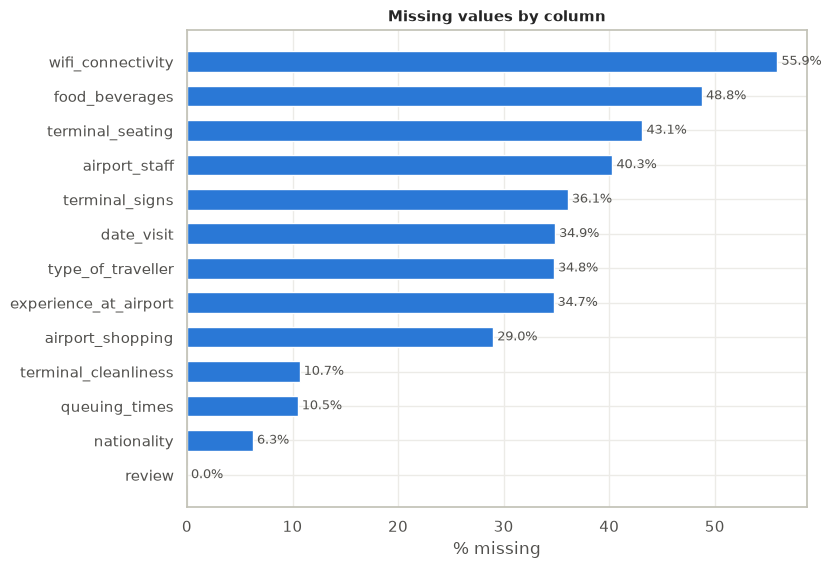

In [20]:
if len(missing):
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(missing) + 1))
    ax.barh(missing.index, missing["pct_missing"], color=MAIN, height=0.6)
    ax.invert_yaxis()
    ax.set_xlabel("% missing")
    ax.set_title("Missing values by column")
    for i, v in enumerate(missing["pct_missing"]):
        ax.text(v, i, f" {v:.1f}%", va="center", color="#52514e", fontsize=9)
    save_fig(fig, "missing_values")
    plt.show()

In [21]:
# Do nulls co-occur? (same rows missing several fields -> one upstream cause)
if len(missing) > 1:
    display(df[missing.index].isna().corr().round(2))

,wifi_connectivity,food_beverages,terminal_seating,airport_staff,terminal_signs,date_visit,type_of_traveller,experience_at_airport,airport_shopping,terminal_cleanliness,queuing_times,nationality,review
wifi_connectivity,1.00,0.68,0.69,0.64,0.63,0.65,0.65,0.65,0.27,0.31,0.30,0.23,-0.01
food_beverages,0.68,1.00,0.84,0.73,0.72,0.74,0.75,0.75,0.40,0.35,0.35,0.26,-0.00
terminal_seating,0.69,0.84,1.00,0.80,0.81,0.84,0.84,0.84,0.25,0.40,0.39,0.30,-0.00
airport_staff,0.64,0.73,0.80,1.00,0.91,0.89,0.89,0.89,0.12,0.41,0.42,0.31,-0.00
terminal_signs,0.63,0.72,0.81,0.91,1.00,0.97,0.97,0.97,0.03,0.45,0.45,0.34,-0.00
date_visit,0.65,0.74,0.84,0.89,0.97,1.00,1.00,1.00,0.03,0.46,0.47,0.35,-0.00
type_of_traveller,0.65,0.75,0.84,0.89,0.97,1.00,1.00,1.00,0.03,0.46,0.47,0.35,-0.00
experience_at_airport,0.65,0.75,0.84,0.89,0.97,1.00,1.00,1.00,0.03,0.46,0.47,0.35,-0.00
airport_shopping,0.27,0.40,0.25,0.12,0.03,0.03,0.03,0.03,1.00,0.53,0.52,0.40,-0.00
terminal_cleanliness,0.31,0.35,0.40,0.41,0.45,0.46,0.46,0.46,0.53,1.00,0.96,0.74,-0.00


In [22]:
# Rows with a missing TARGET cannot be used for supervised training
if TARGET and df[TARGET].isna().any():
    print(f"{df[TARGET].isna().sum()} rows have no {TARGET} -> drop before modelling")

## 4.2 Outliers<a id="sec-4-2"></a>

**Detect, don't delete.** Flag values outside `Q1 - 1.5·IQR` / `Q3 + 1.5·IQR`, then decide per column:
real but rare (keep, maybe log-transform) vs. error (fix in 3.5).

In [23]:
num_cols = [c for c in df.select_dtypes("number").columns
            if c not in ID_COLS and df[c].nunique() > 2]
if num_cols:
    outliers = outlier_report(df, num_cols)
    display(outliers[outliers.n_outliers > 0])
else:
    print("No numeric columns besides the id: nothing to check.")

,lower,upper,min,max,n_outliers,pct_outliers
column,,,,,,


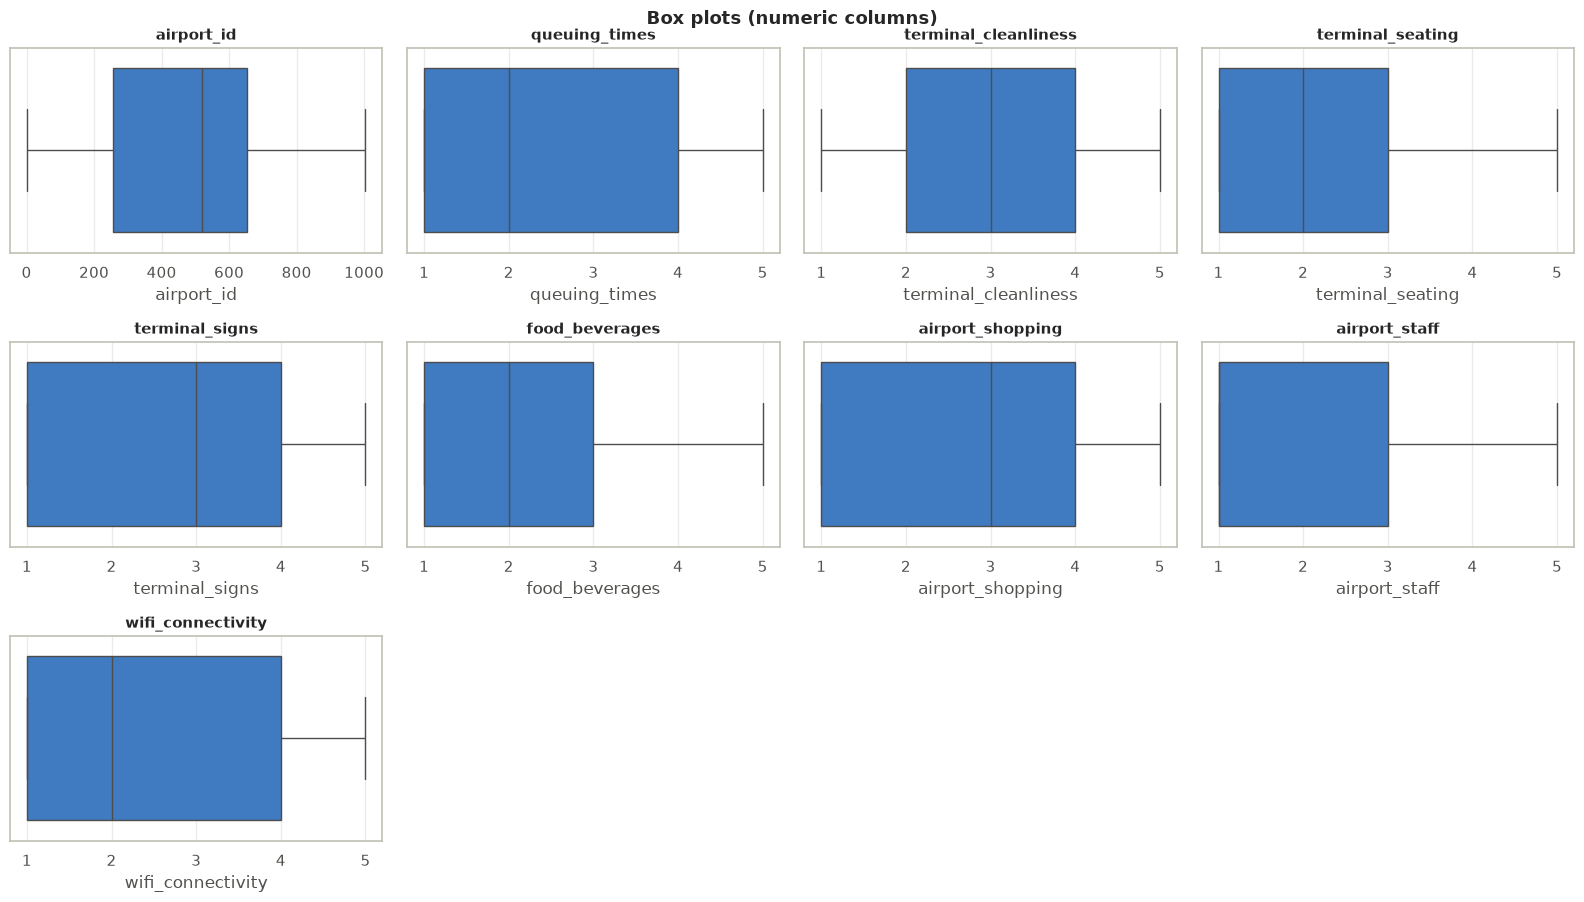

In [24]:
plot_grid(num_cols, lambda c, ax: sns.boxplot(x=df[c], ax=ax, color=MAIN, fliersize=3, linewidth=1),
          title="Box plots (numeric columns)", name="boxplots")

# 5. Attribute Combination<a id="sec-5"></a>

Create features that may explain the data better than the raw columns (ratios, rates, flags, date parts).
They go through the same EDA as everything else below.

how long after the trip the review was written, review length, how many ratings were filled in, review year.

In [25]:
# How long after the trip was the review written, how long is it, and how many ratings were filled in?
visit_col = next((c for c in ["date_flown", "date_visit"] if c in df.columns), None)
rating_cols = df.select_dtypes("float").columns.tolist()
if visit_col:
    df["days_to_review"] = (df["date_submitted"] - df[visit_col]).dt.days
df["review_length"] = df["review"].str.len()
df["n_ratings_filled"] = df[rating_cols].notna().sum(axis=1)
df["submitted_year"] = df["date_submitted"].dt.year


# 6. EDA<a id="sec-6"></a>

## 6.0 Classify Attributes<a id="sec-6-0"></a>

Every plot below is driven by these groups. Override with `CAT_COLS` in the config if a group looks wrong.

In [26]:
groups = classify_columns(df, TARGET, ID_COLS, CAT_COLS, CAT_MAX_UNIQUE)
for name, cols in groups.items():
    print(f"{name:<12} ({len(cols):>2}): {cols}")

const_attribs = groups["constant"]
bin_attribs = groups["binary"]
cat_attribs = groups["categorical"]
disc_attribs = groups["discrete"]
cont_attribs = groups["continuous"]
num_attribs = disc_attribs + cont_attribs

constant     ( 1): ['updated_at']
binary       ( 1): ['verify']
categorical  ( 8): ['airport_id', 'date_submitted', 'date_visit', 'customer_name', 'nationality', 'experience_at_airport', 'type_of_traveller', 'review']
discrete     ( 9): ['queuing_times', 'terminal_cleanliness', 'terminal_seating', 'terminal_signs', 'food_beverages', 'airport_shopping', 'airport_staff', 'wifi_connectivity', 'n_ratings_filled']
continuous   ( 3): ['days_to_review', 'review_length', 'submitted_year']


In [27]:
# Constant columns carry no information
if const_attribs:
    print("Dropping constant columns:", const_attribs)
    df = df.drop(columns=const_attribs)

# High-cardinality text columns (e.g. free text, raw model names) swamp plots
high_card = [c for c in cat_attribs if df[c].nunique() > 50]
print("High-cardinality categoricals (summarised, not plotted):", high_card)
cat_plot_attribs = [c for c in cat_attribs if c not in high_card]

Dropping constant columns: ['updated_at']
High-cardinality categoricals (summarised, not plotted): ['airport_id', 'date_submitted', 'date_visit', 'customer_name', 'nationality', 'review']


## 6.1 Univariate<a id="sec-6-1"></a>

One column at a time: shape, spread, skew, rare levels.

### 6.1.1 Target

The target is `recommended`: the share of reviews that recommend (class balance). A rate far from 50% is normal here; it is the baseline every segment is compared with.

,count,pct
recommended,,
False,37758,76.41
True,11654,23.59


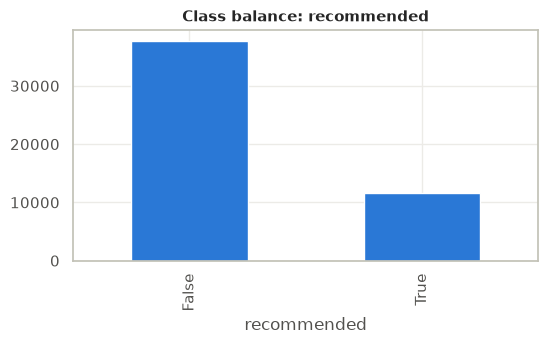

In [28]:
if TARGET and PROBLEM_TYPE == "regression":
    y = df[TARGET].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.histplot(y, kde=True, ax=axes[0], color=MAIN)
    axes[0].set_title(f"{TARGET} (skew = {y.skew():.2f})")
    sns.histplot(np.log1p(y), kde=True, ax=axes[1], color=MAIN)
    axes[1].set_title(f"log1p({TARGET}) (skew = {np.log1p(y).skew():.2f})")
    fig.tight_layout()
    save_fig(fig, "target_distribution")
    plt.show()
    display(y.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame())
elif TARGET:
    counts = df[TARGET].value_counts()
    display(pd.DataFrame({"count": counts, "pct": counts / counts.sum() * 100}))
    fig, ax = plt.subplots(figsize=(6, 3))
    counts.plot.bar(ax=ax, color=MAIN)
    ax.set_title(f"Class balance: {TARGET}")
    save_fig(fig, "target_distribution")
    plt.show()

### 6.1.2 Numeric

In [29]:
skew = df[num_attribs].skew().sort_values(key=abs, ascending=False).to_frame("skew")
skew["shape"] = pd.cut(skew["skew"].abs(), [-np.inf, 0.5, 1, np.inf], labels=["symmetric", "moderate", "highly skewed"])
skew

,skew,shape
days_to_review,4.72,highly skewed
review_length,2.12,highly skewed
airport_staff,0.82,moderate
queuing_times,0.57,moderate
food_beverages,0.55,moderate
terminal_seating,0.55,moderate
n_ratings_filled,-0.52,moderate
wifi_connectivity,0.38,symmetric
airport_shopping,0.31,symmetric
submitted_year,-0.30,symmetric


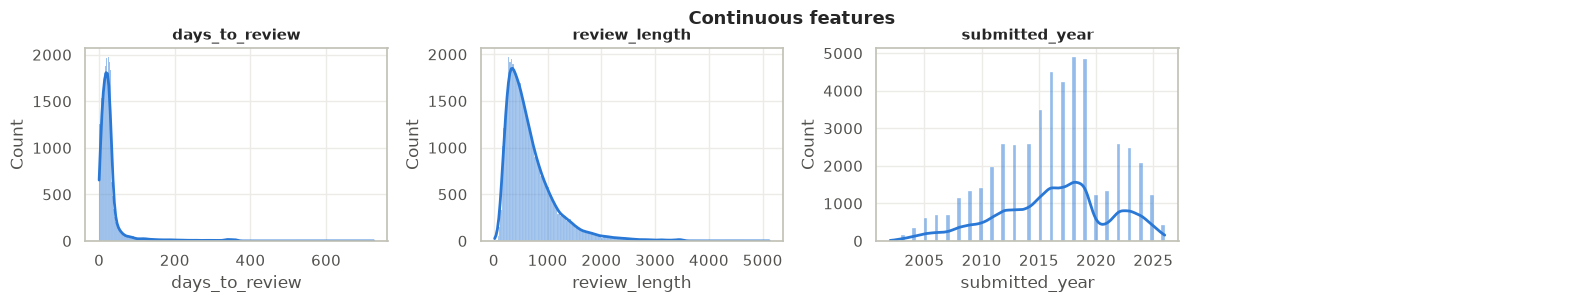

In [30]:
plot_grid(cont_attribs, lambda c, ax: sns.histplot(df[c], kde=True, ax=ax, color=MAIN),
          title="Continuous features", name="hist_continuous")

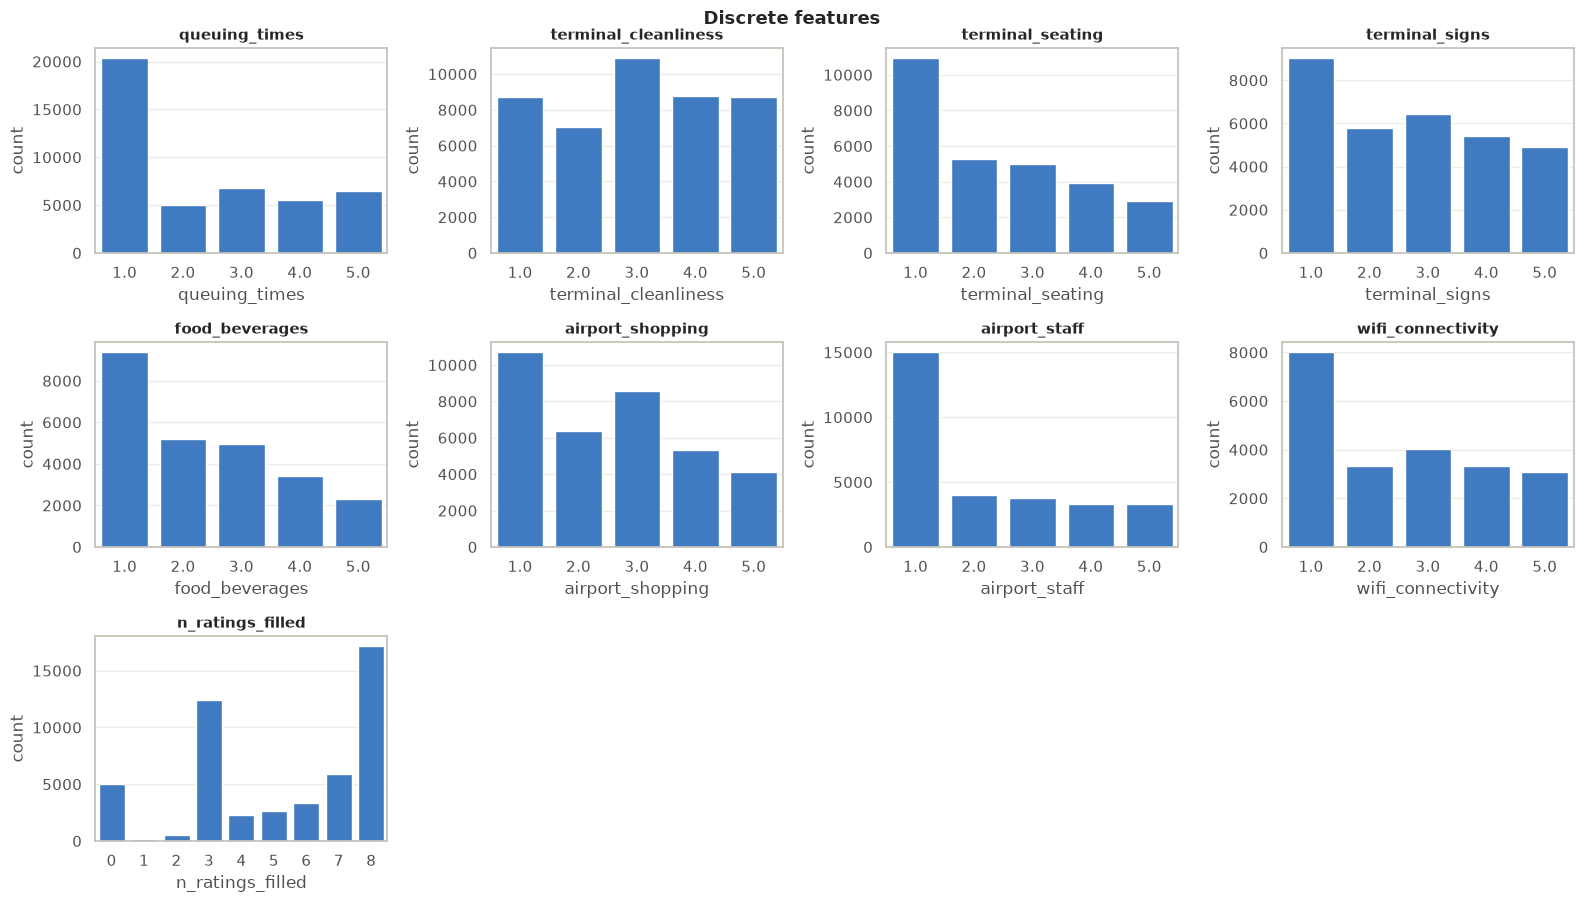

In [31]:
plot_grid(disc_attribs, lambda c, ax: sns.countplot(x=df[c], ax=ax, color=MAIN),
          title="Discrete features", name="count_discrete")

### 6.1.3 Binary

In [32]:
if bin_attribs:
    binary_share = (df[bin_attribs]
                    .apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
                    .sort_values(ascending=False)
                    .to_frame("pct_majority_value"))
    binary_share["near_constant"] = binary_share["pct_majority_value"] > 95
    display(binary_share)
else:
    print("No binary columns.")

,pct_majority_value,near_constant
verify,78.41,False


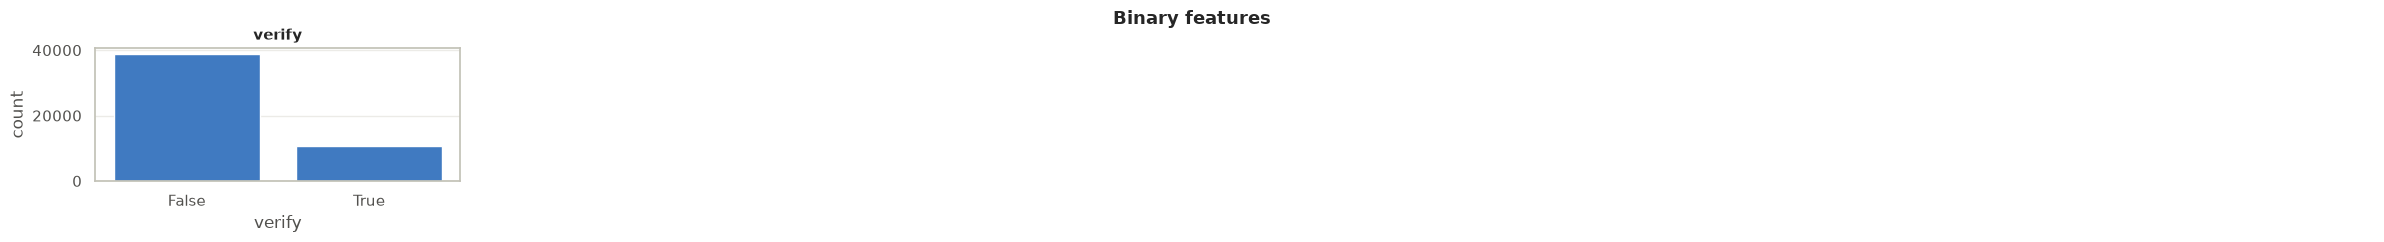

In [33]:
plot_grid(bin_attribs, lambda c, ax: sns.countplot(x=df[c], ax=ax, color=MAIN),
          ncols=6, height=2.4, title="Binary features", name="count_binary")

### 6.1.4 Categorical

In [34]:
for col in high_card:
    print(f"{col}: {df[col].nunique()} levels; top 5:")
    display(df[col].value_counts().head(5).to_frame())

airport_id: 1004 levels; top 5:


,count
airport_id,
562,1397
529,1051
530,938
688,842
541,805


date_submitted: 6171 levels; top 5:


,count
date_submitted,
2014-09-01,68
2015-03-17,65
2015-01-19,65
2014-10-13,60
2015-01-14,59


date_visit: 144 levels; top 5:


,count
date_visit,
2016-07-01,520
2018-06-01,499
2017-07-01,491
2019-06-01,476
2019-07-01,470


... (2 outputs left out)

nationality: 1845 levels; top 5:


,count
nationality,
United Kingdom,15783
United States,8857
Australia,3034
Canada,1943
Germany,1106


review: 48818 levels; top 5:


,count
review,
✅ Trip Verified,3
Its clean and the queues were practically non-existent when I went through (they seemed to be manning more counters than there were customers both at check-in and immigration. Yes I agree with some people that the staff have not been trained as well as at other airports and many don't seem to know anything or just want to pass you on to someone else but in general everything at this new terminal is self-explanatory. I found the signage to be clear and sufficient.,2
Arrival from Stansted a breeze straight through immigration. On departure 10 minutes through to departures. Not keen on being forced to walk through tax free shopping area. New terminal very bright and airy although a long walk to Ryanair departure at area B. Extensive catering choice but as has been said already prices very expensive.,2
I have been using this airport regularly for over 16 years and it is getting worse and certainly can no longer consider itself one of the best in the world. The lounges and shopping areas are great but the unbelievably longer queues throughly security at departures (55mins) and then 30mins at passport controls at arrivals is unacceptable. Arriving early doesn't solve anything as the baggage drop off desks are often closed until 2hrs before departures. I am glad we have chosen to travel by ferry and not fly this coming Summer as Schiphol should be avoided.,2
"Simply the worst airport experience ever in my 35 years of traveling experience. From check in to security, the staff were unhelpful, rude and inefficient, traveler's basic ease is ignored and is a herculean task to navigate. An airport that sets the standards as worst ever.",2


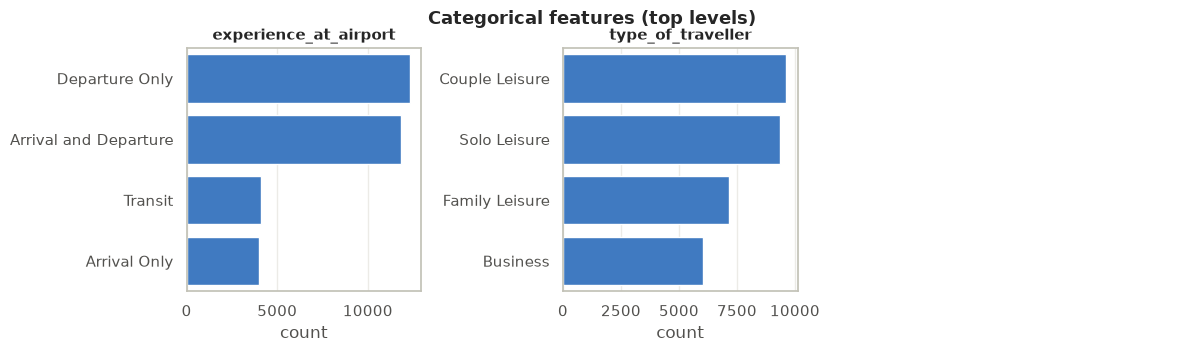

In [35]:
def plot_top_categories(col, ax):
    counts = df[col].value_counts()
    top = counts.head(TOP_N_CATEGORIES)
    sns.barplot(x=top.values, y=top.index.astype(str), ax=ax, color=MAIN, orient="h")
    ax.set_xlabel("count")
    ax.set_ylabel("")

plot_grid(cat_plot_attribs, plot_top_categories, ncols=3, height=3.5,
          title="Categorical features (top levels)", name="count_categorical")

In [36]:
# Rare levels (< 1% of rows) - candidates for grouping into "other"
rare = {c: df[c].value_counts(normalize=True).loc[lambda s: s < 0.01].index.tolist() for c in cat_plot_attribs}
{c: v for c, v in rare.items() if v}

{}

## 6.2 Bivariate<a id="sec-6-2"></a>

Each feature against **`recommended`**. This is where the candidate drivers come from. The charts show, for each rating value, the share of reviews that recommend; the last cell ranks the ratings by how strongly they move with `recommended`.

In [37]:
if TARGET and PROBLEM_TYPE == "regression":
    target_corr = (df[num_attribs + bin_attribs + [TARGET]]
                   .corr(method="spearman")[TARGET]
                   .drop(TARGET)
                   .sort_values(key=abs, ascending=False))
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(target_corr) + 1))
    colors = np.where(target_corr > 0, PALETTE[7], PALETTE[0])
    ax.barh(target_corr.index, target_corr.values, color=colors, height=0.7)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.invert_yaxis()
    ax.set_xlabel(f"Spearman correlation with {TARGET}")
    ax.set_title(f"Features ranked by correlation with {TARGET}")
    save_fig(fig, "target_correlation")
    plt.show()

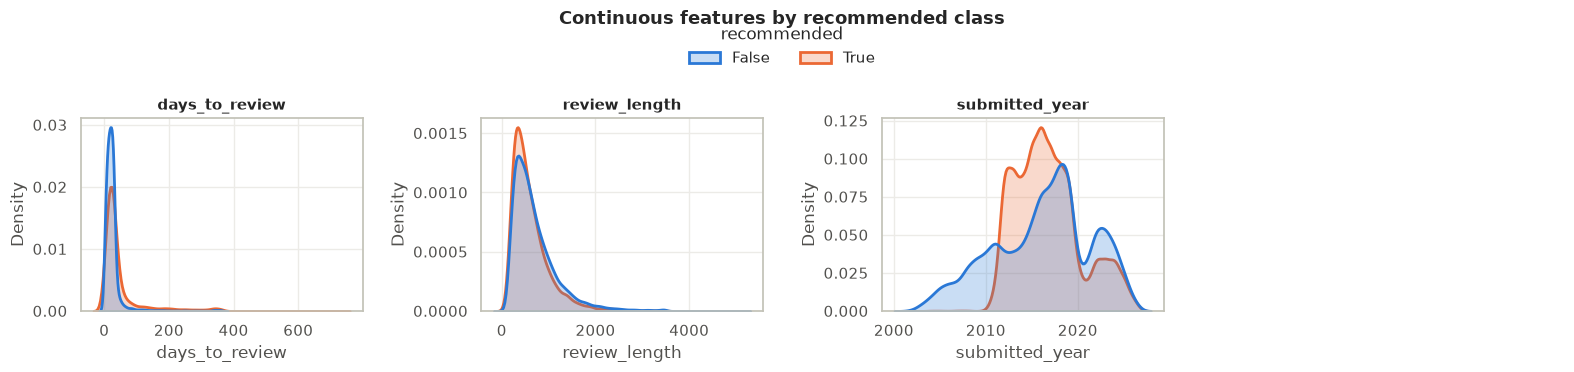

In [38]:
if TARGET and PROBLEM_TYPE == "regression":
    top_num = [c for c in target_corr.index if c in cont_attribs][:8]
    plot_grid(top_num,
              lambda c, ax: sns.regplot(data=df, x=c, y=TARGET, ax=ax, lowess=True,
                                        scatter_kws={"s": 8, "alpha": 0.35, "color": MAIN},
                                        line_kws={"color": PALETTE[1]}),
              title=f"Top continuous features vs {TARGET} (LOWESS trend)", name="scatter_vs_target")
elif TARGET:
    plot_grid(cont_attribs,
              lambda c, ax: sns.kdeplot(data=df, x=c, hue=TARGET, common_norm=False, fill=True,
                                        alpha=0.25, linewidth=2, ax=ax),
              title=f"Continuous features by {TARGET} class", name="dist_by_target", shared_legend=True)

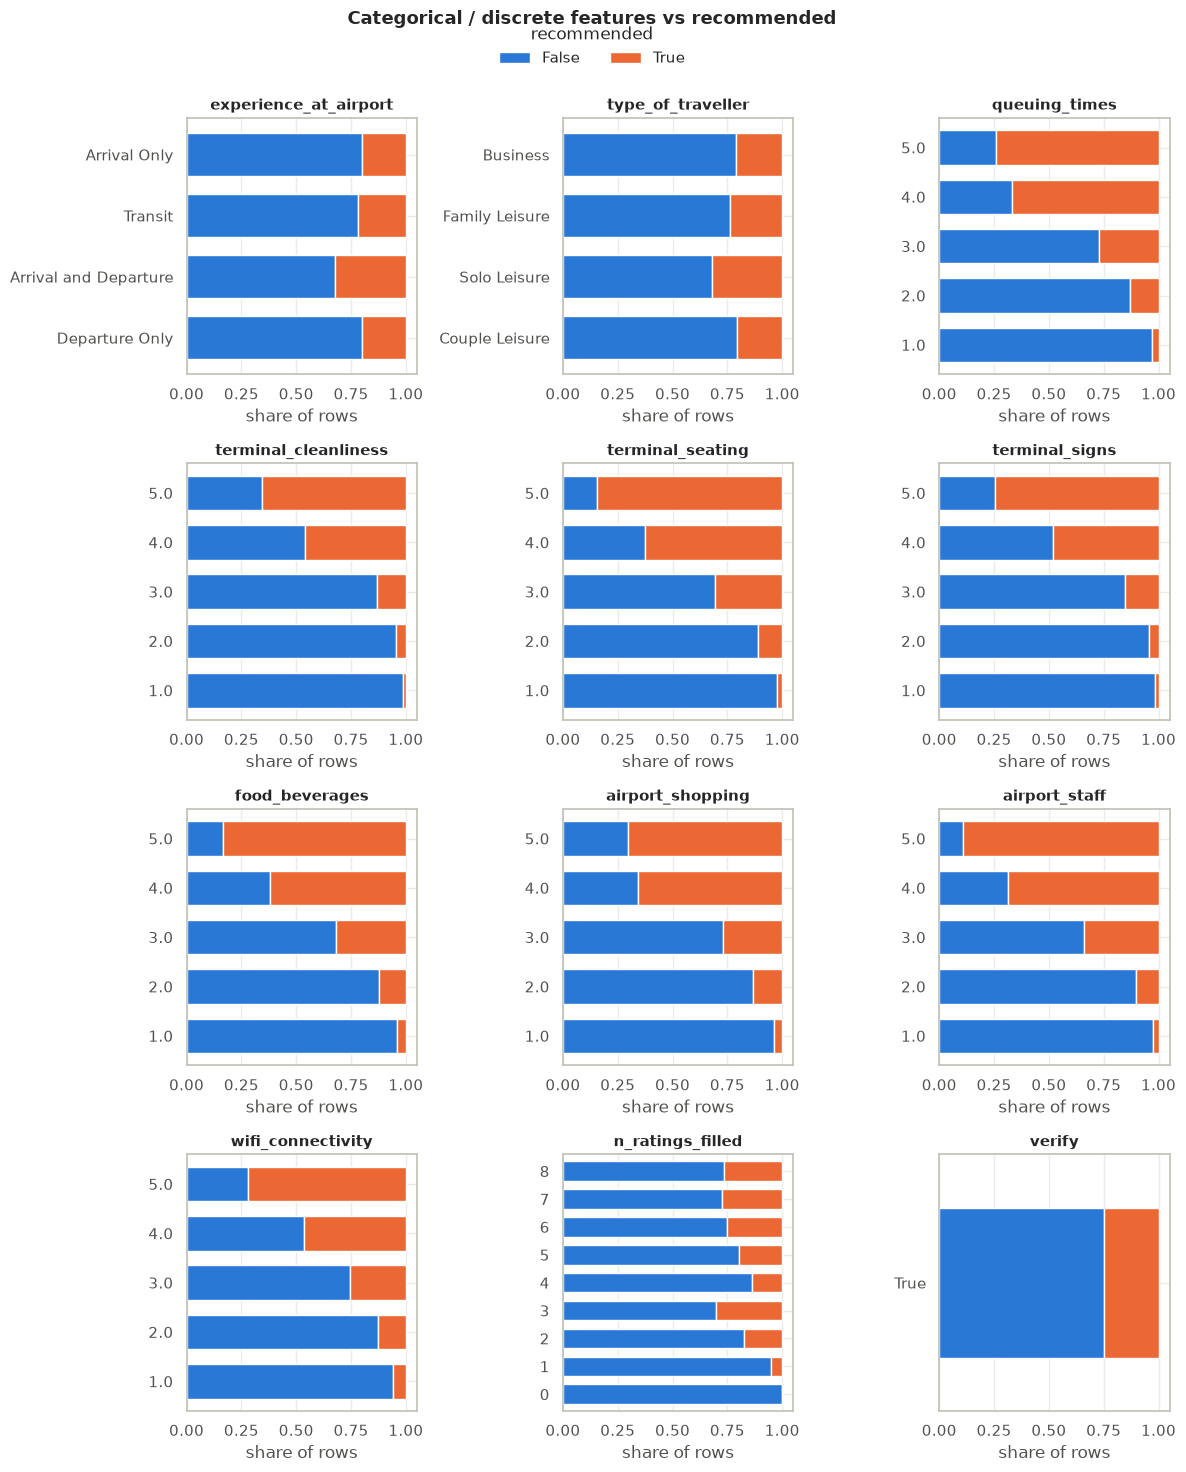

In [39]:
def plot_cat_vs_target(col, ax):
    order = df[col].value_counts().head(TOP_N_CATEGORIES).index
    if pd.api.types.is_numeric_dtype(df[col]):
        order = order.sort_values()
    if PROBLEM_TYPE == "regression":
        sns.boxplot(data=df[df[col].isin(order)], x=TARGET, y=col, order=order,
                    ax=ax, color=MAIN, fliersize=2, linewidth=1, orient="h")
    else:
        rate = pd.crosstab(df[col], df[TARGET], normalize="index").loc[order]
        rate.plot.barh(stacked=True, ax=ax, width=0.7, edgecolor="white", linewidth=1)
        ax.set_xlabel("share of rows")
    ax.set_ylabel("")

if TARGET:
    by_level = cat_plot_attribs + disc_attribs + (bin_attribs if PROBLEM_TYPE == "classification" else [])
    plot_grid(by_level, plot_cat_vs_target, ncols=3, height=3.5,
              title=f"Categorical / discrete features vs {TARGET}", name="cat_vs_target", shared_legend=True)

In [40]:
# Binary flags: difference in median target between the two groups (a = lower value, b = higher)
if TARGET and PROBLEM_TYPE == "regression":
    rows = {}
    for col in bin_attribs:
        a, b = sorted(df[col].dropna().unique())
        y_a, y_b = df.loc[df[col] == a, TARGET].dropna(), df.loc[df[col] == b, TARGET].dropna()
        rows[col] = {"a": a, "b": b, "median_when_a": y_a.median(), "median_when_b": y_b.median(),
                     "share_of_b": (df[col] == b).mean(), "p_value": stats.mannwhitneyu(y_a, y_b).pvalue}
    lift = pd.DataFrame(rows).T
    lift["diff"] = (lift["median_when_b"] - lift["median_when_a"]).astype(float)
    display(lift.sort_values("diff", key=abs, ascending=False))

In [41]:
# Which rating moves most with `recommended`? Spearman correlation of each rating with recommended (0/1).
# "Goes with", not "causes": this is observed data.
rating_cols = [c for c in df.select_dtypes("float").columns if c in MEANINGS]
recommended_01 = df[TARGET].astype("float")
driver_rank = (df[rating_cols].apply(lambda s: s.corr(recommended_01, method="spearman"))
               .sort_values(ascending=False).to_frame("spearman_with_recommended"))
driver_rank["n_rated"] = df[rating_cols].notna().sum()
display(driver_rank.round(2))

# Same ranking inside each of the 3 biggest segments (experience_at_airport): does the order change?
segment_col = "experience_at_airport"
top_segments = df[segment_col].value_counts().head(3).index
by_segment = pd.DataFrame({
    seg: df.loc[df[segment_col] == seg, rating_cols].apply(
        lambda s: s.corr(df.loc[df[segment_col] == seg, TARGET].astype("float"), method="spearman"))
    for seg in top_segments})
display(by_segment.round(2))


,spearman_with_recommended,n_rated
airport_staff,0.67,29495
queuing_times,0.61,44222
terminal_seating,0.60,28091
terminal_signs,0.58,31585
food_beverages,0.56,25302
terminal_cleanliness,0.54,44133
airport_shopping,0.54,35077
wifi_connectivity,0.50,21776


,Departure Only,Arrival and Departure,Transit
queuing_times,0.57,0.69,0.61
terminal_cleanliness,0.52,0.62,0.55
terminal_seating,0.56,0.66,0.59
terminal_signs,0.52,0.64,0.58
food_beverages,0.51,0.61,0.57
airport_shopping,0.50,0.57,0.56
airport_staff,0.61,0.71,0.66
wifi_connectivity,0.46,0.55,0.48


## 6.3 Multivariate<a id="sec-6-3"></a>

Features against **each other**: redundancy, leakage, interactions.

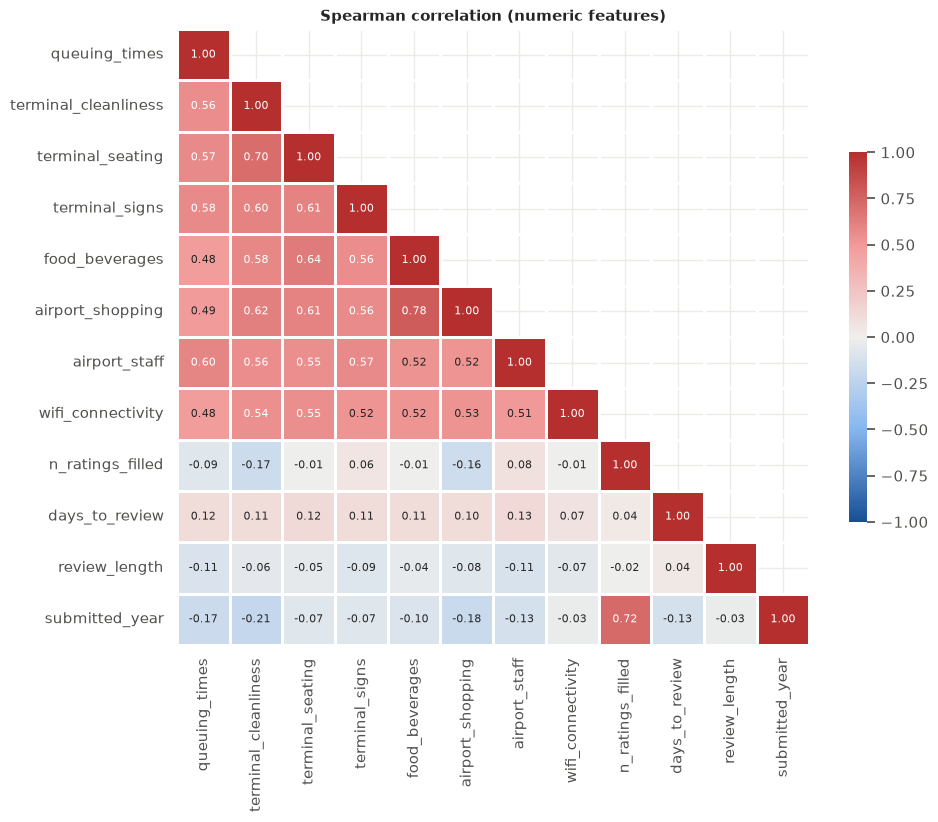

In [42]:
corr_cols = num_attribs
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(method="spearman")
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    fig, ax = plt.subplots(figsize=(0.6 * len(corr) + 3, 0.5 * len(corr) + 2))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, center=0,
                linewidths=2, linecolor="white", annot_kws={"size": 8}, cbar_kws={"shrink": 0.6}, ax=ax)
    ax.set_title("Spearman correlation (numeric features)")
    save_fig(fig, "correlation_heatmap")
    plt.show()
else:
    print("Fewer than two numeric columns: no correlation to show.")

In [43]:
# Highly correlated pairs -> keep one of each pair (or combine) before modelling
if len(corr_cols) >= 2:
    pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
             .stack()
             .rename("r")
             .reset_index()
             .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
    display(pairs[pairs.r.abs() >= HIGH_CORR].sort_values("r", key=abs, ascending=False))

,feature_a,feature_b,r


In [44]:
# Leakage check: ID columns or row order should NOT predict the target
if TARGET and PROBLEM_TYPE == "regression":
    for col in ID_COLS:
        if col in df.columns:
            r = df[[col, TARGET]].corr(method="spearman").iloc[0, 1]
            print(f"corr({col}, {TARGET}) = {r:.2f}" + ("  <-- rows are ordered; shuffle before splitting" if abs(r) > 0.3 else ""))

### 6.3.1 Segments

Three views that answer the business questions: (1) the mean rating and recommend rate of each segment (`HUE`), (2) the trend by review year, (3) how many airlines or airports have enough reviews to be compared.
Hue splits use at most 3 groups; smaller groups fold into "other".

,n_reviews,recommend_rate
experience_at_airport,,
Departure Only,12336,0.20
Arrival and Departure,11836,0.32
Transit,4091,0.22
other,3992,0.20


experience_at_airport,Arrival and Departure,Departure Only,Transit,other
queuing_times,2.41,2.15,2.19,1.90
terminal_cleanliness,2.94,2.77,2.92,2.82
terminal_seating,2.52,2.26,2.43,2.26
terminal_signs,2.87,2.66,2.60,2.66
food_beverages,2.49,2.23,2.41,2.36
airport_shopping,2.53,2.29,2.54,2.38
airport_staff,2.42,2.03,2.08,2.03
wifi_connectivity,2.66,2.47,2.55,2.42


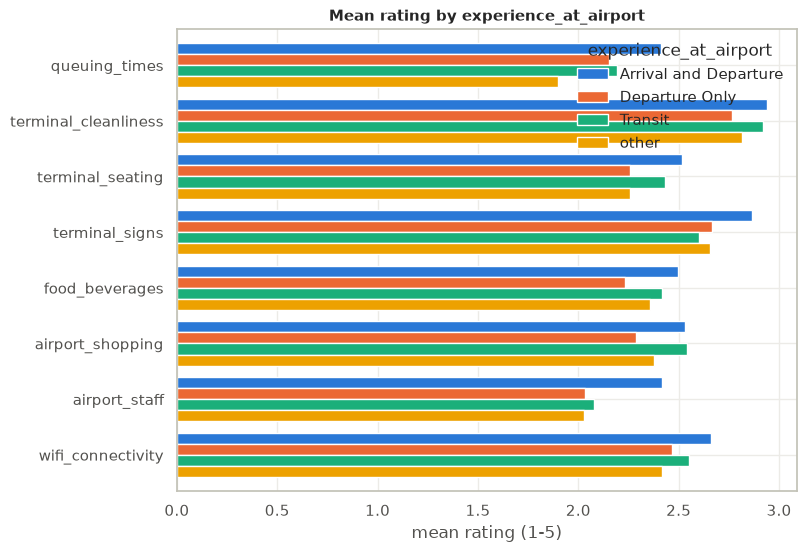

In [45]:
HUE = "experience_at_airport"   # the column that splits the rows into segments

if HUE in df.columns:
    # Keep the 3 biggest groups, fold the rest into "other"
    segmented = df[df[HUE].notna()]
    keep = segmented[HUE].value_counts().head(3).index
    segmented = segmented.assign(**{HUE: segmented[HUE].where(segmented[HUE].isin(keep), "other")})

    rating_cols = [c for c in df.select_dtypes("float").columns if c in MEANINGS]
    mean_rating = segmented.groupby(HUE)[rating_cols].mean().T      # rows = ratings, columns = segments
    segment_size = segmented[HUE].value_counts().to_frame("n_reviews")
    segment_size["recommend_rate"] = segmented[TARGET].astype("float").groupby(segmented[HUE]).mean()
    display(segment_size.round(2))
    display(mean_rating.round(2))

    fig, ax = plt.subplots(figsize=(8, 0.5 * len(rating_cols) + 2))
    mean_rating.plot.barh(ax=ax, width=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("mean rating (1-5)")
    ax.set_title(f"Mean rating by {HUE}")
    ax.legend(title=HUE, frameon=False)
    plt.show()


,n_reviews,recommend_rate,queuing_times,terminal_cleanliness,terminal_seating,terminal_signs,food_beverages,airport_shopping,airport_staff,wifi_connectivity
submitted_year,,,,,,,,,,
2002,24,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2003,171,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2004,355,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005,607,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006,700,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007,704,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008,1139,0.00,3.00,3.00,NaN,NaN,NaN,1.00,NaN,NaN
2009,1331,0.00,3.30,3.77,NaN,NaN,NaN,3.17,NaN,NaN
2010,1417,0.00,2.96,3.63,4.00,NaN,4.00,2.82,4.00,NaN


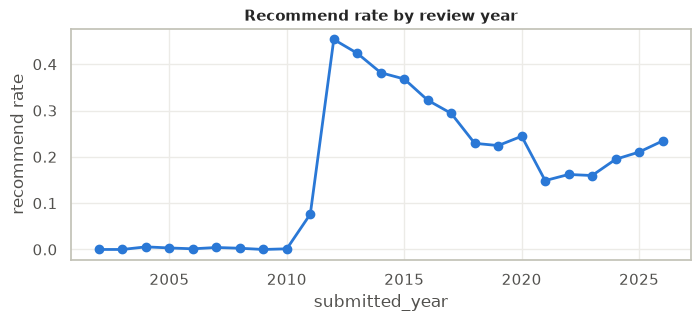

In [46]:
# Trend by review year: number of reviews, recommend rate and mean rating of each aspect
rating_cols = [c for c in df.select_dtypes("float").columns if c in MEANINGS]
yearly = df.groupby("submitted_year").agg(n_reviews=("review_id", "size"))
yearly["recommend_rate"] = df[TARGET].astype("float").groupby(df["submitted_year"]).mean()
display(yearly.round(2).join(df.groupby("submitted_year")[rating_cols].mean().round(2)))

fig, ax = plt.subplots(figsize=(8, 3))
yearly["recommend_rate"].plot(ax=ax, marker="o", color=MAIN)
ax.set_ylabel("recommend rate")
ax.set_title("Recommend rate by review year")
plt.show()


In [47]:
# Peer rule: only compare a airport that has at least 100 reviews
reviews_per_airport = df["airport_id"].value_counts()
enough = reviews_per_airport >= 100
print(f"{enough.sum()} of {len(enough)} airports have at least 100 reviews")
print(f"They hold {reviews_per_airport[enough].sum() / len(df):.0%} of all reviews")


134 of 1004 airports have at least 100 reviews
They hold 74% of all reviews


In [48]:
# Pairplot of the strongest features (slow on wide data - keep it small)
if TARGET and PROBLEM_TYPE == "regression":
    pp_cols = [c for c in target_corr.index if c in cont_attribs][:4] + [TARGET]
    g = sns.pairplot(df[pp_cols].dropna(), corner=True, plot_kws={"s": 8, "alpha": 0.35, "color": MAIN},
                     diag_kws={"color": MAIN})
    g.figure.suptitle("Pairplot: strongest continuous features", y=1.02)
    save_fig(g.figure, "pairplot")
    plt.show()

# 7. Summary of Findings<a id="sec-7"></a>

The deliverable: one answer per question from 1.2, then the actions before staging. Drafted from the data, to be reviewed.
*Numbers come from running this notebook on the CSV. Counts printed from 3.5 onward are taken after the duplicates dropped in 3.4, so they can be slightly lower than counts on the raw file.*

**Answers to the questions in 1.2**
| # | Answer |
|---|---|
| D1 | Usable after cleaning: `nationality` is polluted with free text. |
| Q1 | 134 of 1,004 airports have at least 100 reviews and hold 74% of the reviews. For departure-only visitors the lowest mean ratings are `airport_staff` (2.03) and `queuing_times` (2.15); wifi and cleanliness are higher. |
| Q2 | `airport_staff` goes with `recommended` the most (Spearman 0.67), then `queuing_times` 0.61, `terminal_seating` 0.60, `terminal_signs` 0.58, `food_beverages` 0.56; `wifi_connectivity` is lowest (0.50). |
| Q3 | Arrival-and-departure visitors rate everything higher (recommend rate 32%) than departure-only (20%) and transit (22%) visitors. `airport_staff` is the strongest driver in all three groups. |
| Q4 | No pair of ratings reaches 0.8 (closest: `food_beverages`-`airport_shopping` 0.78). |

**Data quality**
* 49,505 rows x 20 columns; 93 rows are identical except `review_id` (49,412 after 3.4).
* `nationality`: 1,011 of 46,322 values do not look like a country (`Terminal 2`, `45min`, ...); 1,845 distinct values for about 200 countries.
* `customer_name` ends with a number in 47,722 rows; 1,185 rows share their review text with another row, 42 of them for the same airport.
* 1 review is empty and 3 are shorter than 20 characters (a marker only).
* Real missing data (do not fill): `wifi_connectivity` 55.9%, `food_beverages` 48.8%, `terminal_seating` 43.2%, `airport_staff` 40.3%, `terminal_signs` 36.1%, `date_visit` 34.9%, `type_of_traveller` 34.8%, `experience_at_airport` 34.7%.

**Target**
* `recommended`: 23.6% of the reviews recommend. The rate is about 0% until 2010, 45% in 2012, 22% in 2019 and 15-16% in 2021-2023: the flag was probably not recorded before 2011, so use 2012 onward.

**Key drivers**
* Spearman with `recommended`: `airport_staff` 0.67, `queuing_times` 0.61, `terminal_seating` 0.60, `terminal_signs` 0.58, `food_beverages` 0.56, `terminal_cleanliness` 0.54, `airport_shopping` 0.54, `wifi_connectivity` 0.50.

**Redundancy / leakage**
* No pair of ratings is at or above `HIGH_CORR` (0.8).
* `n_ratings_filled` rises strongly with the review year (0.72): the form changed, so empty ratings in old years are not low scores.

**Actions before staging**
| Action | Column(s) | Why |
|---|---|---|
| Keep only values found in the `countries` seed, null the rest | `nationality` | free text leaked in |
| Strip the trailing number | `customer_name` | not part of a real name |
| Keep one row of identical duplicates | all columns except `review_id` | duplicate reviews |
| Drop | `updated_at` | one value for all rows |
| Use reviews from 2012 on for recommend-rate comparisons | `date_submitted` | flag not recorded before |
| Do not fill nulls | ratings, `date_visit`, `type_of_traveller`, `experience_at_airport` | real missing data |


# 8. Hand-off to Modelling<a id="sec-8"></a>

Next steps (the template's modelling checklist does not apply: there is no model):

1. **Write the staging model** `stg__airport_reviews` with the cleaning actions from section 7.
2. **Add dbt tests** (`unique`, `not_null`, `relationships`, `accepted_values`) for every rule that can be tested.
3. **Run `dbt run` and `dbt test`**, then compare row counts and null counts with the numbers in this notebook.
4. **Build the star schema** (facts and dimensions) on top of the staging models.